# Task 1: Supervised learning 

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42

def set_seed(seed = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
         torch.cuda.manual_seed_all(seed)

    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SEED)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))# normal mnist normalization using mean 0.130and std 0.308 of the dataset
])

train_data = datasets.MNIST(root="./data", train=True , download=True, transform=transform)
test_data  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)



100%|██████████| 9.91M/9.91M [00:00<00:00, 19.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.89MB/s]


### Data split

In [ ]:
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

split_generator = torch.Generator().manual_seed(SEED)   

train_subset , val_subset = random_split(train_data, [train_size, val_size], generator = split_generator)

print("Train subset:" , train_size)
print("Validation subset:" , val_size)
print("Test set:" , len(test_data))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:" , device)


Train subset: 48000
Validation subset: 12000
Test set: 10000
Running on: cuda


### Architectures
I compare 3 feed-forward models:

- ShallowNet: a simple baseline with one hidden layer.
- DeepNet: a deeper network with three hidden layers, batch normalization, and dropout.
- DeepNet_2: equal to DeepNet but WITHOUT batch normalization and dropout.



In [3]:
class ShallowNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1  = nn.Linear(784,128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128,10)

    def forward(self, x):
         x = x.view(x.size(0), -1)
         x = self.fc1(x)
         x = self.relu(x)
         x = self.fc2(x)
         return x


class DeepNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.fc2 = nn.Linear(512,256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc4 = nn.Linear(128,10)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = x.view(x.size(0),-1)

        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc3(x)
        x = self.bn3(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc4(x)
        return x


class DeepNet_2(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)
        x = self.relu(x)

        x = self.fc3(x)
        x = self.relu(x)

        x = self.fc4(x)

        return x


### Training and evaluation functions


In [ ]:
def make_loader(dataset, batch_size, shuffle, seed=SEED):
    gen = None
    if shuffle:
        
        gen = torch.Generator().manual_seed(seed)

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=gen)
    return loader


def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            bs = labels.size(0)
            total_loss = total_loss + loss.item() * bs

            _, pred = outputs.max(1)
            total = total + bs
            correct = correct + (pred == labels).sum().item()



    avg_loss = total_loss / total
    avg_acc = 100.0 * correct / total


    return avg_loss, avg_acc


def train_model(model, train_loader, val_loader, lr, epochs, weight_decay=0.0):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for e in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            bs = labels.size(0)
            running_loss = running_loss+loss.item() * bs

            _, pred =   outputs.max(1)
            total    =   total+bs
            correct =   correct+(pred ==labels).sum().item()

        train_losses.append(running_loss / total)
        train_accs.append(100.0*correct / total)

        if val_loader is not None:
            val_loss, val_acc= evaluate(model, val_loader, criterion)
            val_losses.append(val_loss)
            val_accs.append(val_acc)

    return train_losses,train_accs, val_losses, val_accs


def run_validation_experiment(model_class, batch_size, lr, epochs, weight_decay=0.0, seed=SEED):
    set_seed(seed)

    train_loader = make_loader(train_subset, batch_size=batch_size, shuffle=True, seed=seed)
    val_loader = make_loader(val_subset, batch_size=batch_size, shuffle=False, seed=seed)

    model = model_class()

    train_losses, train_accs, val_losses, val_accs = train_model(
        model,
        train_loader,
        val_loader,
        lr = lr,
        epochs = epochs,
        weight_decay = weight_decay     )

    out = {}
    out["train_losses"] = train_losses
    out["train_accs"] = train_accs
    out["val_losses"] = val_losses
    out["val_accs"] = val_accs
    out["best_val_acc"] = max(val_accs)
    out["final_val_acc"] = val_accs[-1]
    return out

def plot_curves(train_losses, train_accs, val_losses, val_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, label='Train loss')
    plt.plot(epochs, val_losses, label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_accs, label='Train accuracy')
    plt.plot(epochs, val_accs, label='Validation accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()


### Hyperparameter search
Identical to the first experiment

In [5]:
def tune_learning_rate(model_class, model_name, lrs_to_try, batch_size=64, epochs=5, weight_decay=0.0):
    print("Tuning learning rate for " + str(model_name))
    results = []

    for lr in lrs_to_try:
        result = run_validation_experiment(
            model_class,
            batch_size = batch_size,
            lr = lr,
            epochs = epochs,
            weight_decay = weight_decay,
            seed = SEED,
        )

        results.append((lr, result["best_val_acc"], result["final_val_acc"]))

        print("lr=" + str(lr) + " , best val acc=" + f"{result['best_val_acc']:.2f}%" +
            ", final val acc=" + f"{result['final_val_acc']:.2f}%"
        )

    best_lr = results[0][0]
    best_score = results[0][1]

    for item in results:
        if item[1] > best_score:
            best_score = item[1]
            best_lr = item[0]

    print("Best learning rate for " + str(model_name) + ": " + str(best_lr) + "\n")
    return best_lr, results


lrs_to_try = [0.1, 0.01, 0.001, 0.0001]

deep_best_lr, deep_lr_results = tune_learning_rate(DeepNet_2, "DeepNet_2", lrs_to_try)


Tuning learning rate for DeepNet_2
lr=0.1 , best val acc=11.32%, final val acc=10.68%
lr=0.01 , best val acc=95.57%, final val acc=95.02%
lr=0.001 , best val acc=97.24%, final val acc=97.24%
lr=0.0001 , best val acc=96.30%, final val acc=96.30%
Best learning rate for DeepNet_2: 0.001



In [7]:
def tune_batch_size(model_class, model_name, batch_sizes, lr, epochs=5, weight_decay=0.0):
    print("Tuning batch size for " + str(model_name))
    results = []

    for bs in batch_sizes:
        result = run_validation_experiment(
            model_class,
            batch_size = bs,
            lr = lr,
            epochs = epochs,
            weight_decay = weight_decay,
            seed = SEED,
        )

        results.append((bs, result["best_val_acc"], result["final_val_acc"]))

        print("batch size=" + str(bs) +" , best val acc=" + f"{result['best_val_acc']:.2f}%" +
            ", final val acc=" + f"{result['final_val_acc']:.2f}%"
        )

    best_bs = results[0][0]
    best_score = results[0][1]

    for item in results:
        if item[1] > best_score:
            best_score = item[1]
            best_bs = item[0]

    print("Best batch size for " + str(model_name) + ": " + str(best_bs) + "\n")
    return best_bs, results


batch_sizes = [32, 64, 128, 256]


deep_best_bs, deep_bs_results = tune_batch_size(
    DeepNet_2, "DeepNet_2", batch_sizes, lr = deep_best_lr
)


Tuning batch size for DeepNet_2
batch size=32 , best val acc=97.24%, final val acc=96.96%
batch size=64 , best val acc=97.24%, final val acc=97.24%
batch size=128 , best val acc=97.46%, final val acc=97.46%
batch size=256 , best val acc=97.22%, final val acc=97.22%
Best batch size for DeepNet_2: 128



In [8]:
def tune_weight_decay(model_class, model_name, weight_decays, lr, batch_size, epochs=10):
    print("Tuning weight decay for " + str(model_name))
    results = []

    for wd in weight_decays:
        result = run_validation_experiment(
            model_class,
            batch_size = batch_size,
            lr = lr,
            epochs = epochs,
            weight_decay = wd,
            seed = SEED,
        )

        results.append((wd, result["best_val_acc"], result["final_val_acc"]))

        print("weight decay=" + str(wd) +
              " , best val acc=" + f"{result['best_val_acc']:.2f}%" +
            " , final val acc=" + f"{result['final_val_acc']:.2f}%"
        )

    best_wd = results[0][0]
    best_score = results[0][1]

    for item in results:
        if item[1] > best_score:
            best_score = item[1]
            best_wd = item[0]

    print("Best weight decay for " + str(model_name) + ": " + str(best_wd) + "\n")
    return best_wd, results


weight_decays = [0.0, 0.0001, 0.001, 0.01]


deep_best_wd, deep_wd_results = tune_weight_decay(
    DeepNet_2, "DeepNet_2", weight_decays, lr = deep_best_lr, batch_size = deep_best_bs
)


Tuning weight decay for DeepNet_2
weight decay=0.0 , best val acc=97.88% , final val acc=97.88%
weight decay=0.0001 , best val acc=97.52% , final val acc=97.44%
weight decay=0.001 , best val acc=97.54% , final val acc=96.84%
weight decay=0.01 , best val acc=95.81% , final val acc=94.84%
Best weight decay for DeepNet_2: 0.0



Reading the notebook now only after having  written the previous code cell in the past, I realized that I mustn t tune the weight decay for this experiment for DeepNet_2. Since I want to compare the 2 deeper models, one regularized and the other not regularized at all. 

At posteriori I was lucky since the weight dacay chosen is 0, so the analysis in the and is still valid

### Final training strategy
Identical to the first experiment

In [9]:
print("Selected hyperparameters")
print("DeepNet_2:   ", deep_best_lr, deep_best_bs, deep_best_wd)



deep_train_loader = make_loader(train_subset, batch_size=deep_best_bs, shuffle=True, seed=SEED)
deep_val_loader = make_loader(val_subset, batch_size=deep_best_bs, shuffle=False, seed=SEED)



print("Training DeepNet_2 on the train/validation split...")
set_seed(SEED)
deep_analysis_model_2 = DeepNet_2()
t_loss2, t_acc2, v_loss2, v_acc2 = train_model(
    deep_analysis_model_2,
    deep_train_loader,
    deep_val_loader,
    lr=deep_best_lr,
    epochs=40,
    weight_decay=deep_best_wd,
)



Selected hyperparameters
DeepNet_2:    0.001 128 0.0
Training DeepNet_2 on the train/validation split...


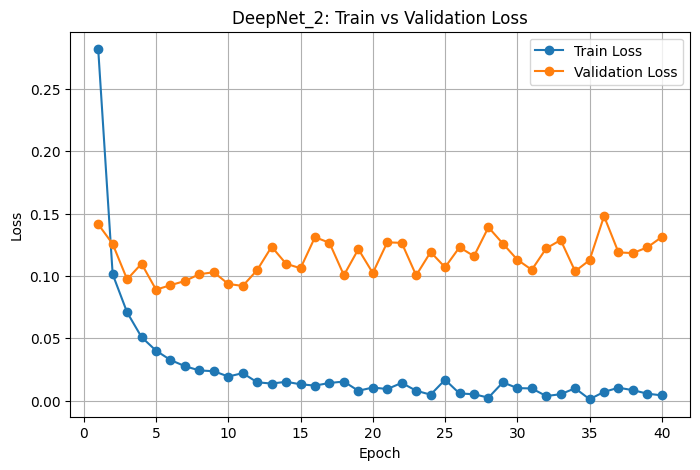

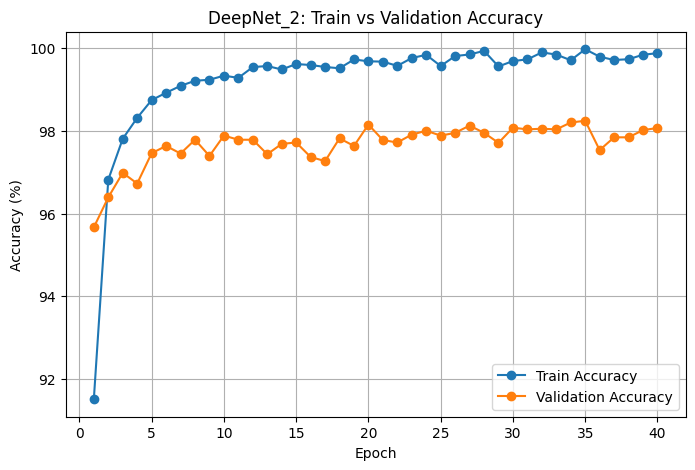

In [11]:
epochs = range(1, 41)
plt.figure(figsize=(8, 5))
plt.plot(epochs, t_loss2, marker='o', label='Train Loss')
plt.plot(epochs, v_loss2, marker='o', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepNet_2: Train vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, t_acc2, marker='o', label='Train Accuracy')
plt.plot(epochs, v_acc2, marker='o', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('DeepNet_2: Train vs Validation Accuracy')
plt.legend()
plt.grid(True)


Comparing with the results in the Task_1_B experiment

In [12]:

test_loader = make_loader(test_data, batch_size=256, shuffle=False, seed=SEED)
deep_analysis_model_2.eval()

deep_test_loss, deep_test_acc_2 = evaluate(deep_analysis_model_2, test_loader, nn.CrossEntropyLoss())
print("\nComparison:")

print(f"DeepNet_2:    train={t_acc2[-1]:.4f}")
print(f"DeepNet_2:    val={v_acc2[-1]:.4f}, test_acc={deep_test_acc_2:.2f}%")


Comparison:
DeepNet_2:    train=99.8750
DeepNet_2:    val=98.0667, test_acc=98.03%


In [ ]:
test_loader = make_loader(test_data, batch_size=256, shuffle=False, seed=SEED)

final_shallow_model = ShallowNet().to(device)
final_deep_model = DeepNet().to(device)
#models from previous A experiment , already trained and saved to disk
final_shallow_model.load_state_dict(torch.load('weights_shallow.pth', map_location=device))
final_deep_model.load_state_dict(torch.load('weights_deep.pth', map_location=device))

criterion = nn.CrossEntropyLoss()
test_loss_shallow, acc_shallow = evaluate(final_shallow_model, test_loader, criterion)
test_loss_deep, acc_deep = evaluate(final_deep_model, test_loader, criterion)

In [ ]:
print("Retraining final models on the full MNIST training set...")


deep_epochs = 40



full_train_loader_deep = make_loader(
    train_data,
    batch_size=deep_best_bs,
    shuffle=True,
    seed=SEED,
)


set_seed(SEED)
deep_model = DeepNet_2()
final_deep_train_losses, final_deep_train_accs, _, _ = train_model(
    deep_model,
    full_train_loader_deep,
    val_loader=None,
    lr=deep_best_lr,
    epochs=deep_epochs,
    weight_decay=deep_best_wd,
)



test_loader = make_loader(test_data, batch_size=256, shuffle=False, seed=SEED)

criterion = nn.CrossEntropyLoss()
test_loss_deep_2, acc_deep_2 = evaluate(deep_model, test_loader, criterion)

print("\nFINAL TEST ACCURACY")
print(f"ShallowNet: {acc_shallow:.2f}%")
print(f"DeepNet:    {acc_deep:.2f}%")
print(f"DeepNet_2:    {acc_deep_2:.2f}%")

Retraining final models on the full MNIST training set...

FINAL TEST ACCURACY
ShallowNet: 98.00%
DeepNet:    98.44%
DeepNet_2:    98.03%


### final comparison on training-validation   


- ShallowNet   <span style="display:inline-block; width:350px;"></span>  
  - Training accuracy: 99.7396%  
  - Validation accuracy: 97.6583%  
  - Test accuracy: 97.80%

- DeepNet    <span style="display:inline-block; width:350px;"></span>
  - Training accuracy: 99.0500%  
  - Validation accuracy: 98.4333%  
  - Test accuracy: 98.29%

- DeepNet\_2<span style="display:inline-block; width:350px;"></span>
  - Training accuracy: 99.8750
  - Validation accuracy: 98.0667%  
  - Test accuracy: 98.03%

### Final test accuracy after retraining on the full training set

 - ShallowNet : 98.00%
 - DeepNet : 98.44%
 - DeepNet\_2: 98.03%

# Final conclusion

First, comparing ShallowNet with the two deeper models shows that, apparently, the model complexity may play a important role. ShallowNet is the simplest architecture, and although it reaches very high training accuracy (99.74%), its validation accuracy is lower (97.66%). In contrast, both deeper models achieve better validation performance: 98.43% for DeepNet and 98.07% for DeepNet_2. This suggests that the shallow model has more limited representational power, and that increasing depth allows the network to learn better features. However, complexity alone could  not be sufficient to obtain the best generalization. The most informative comparison is between DeepNet and DeepNet_2, because they have the same architecture but DeepNet is regularized, while DeepNet_2 is not. Here, the role of regularization becomes  clear: DeepNet achieves a lower training accuracy (99.05% vs 99.88%), but a better validation accuracy (98.43% vs 98.07%) and a better test accuracy (98.29% vs 98.03%). This means that introducing regularization allows the net to overfit less. 

In the 80/20 setup, the deeper models appear to benefit from the increased capacity, but this advantage is not robustly maintained when training across the entire training set... But comparing DeepNet_2 with DeepNet shows that, once sufficient complexity is available, regularization becomes crucial to control overfitting and turn that complexity into good generalization.(98.44% vs 98.29% for DeepNet before and after full training while 98.03% vs 98.03% for DeepNet_2 )

The apparent discrepancy is not really a contradiction, but rather shows that the effects of model complexity and regularization are not equally stable across training regimes. In the 80/20 split setting,  DeepNet architecture outperform ShallowNet but not in the final test set after the full dataset training .However differences observed in the 80/20 setup comes from a single run. Therefore, the differences may depend, in part, on experimental variance.
The important thing is that the comparison between DeepNet and DeepNet_2 remains consistent in both scenarios: same architecture, but the regularized model generalizes better. This means the effect of regularization is more robust than the complexity one alone. therefore, in this experiment , the role of complexity alone becomes less robust.

Finally , the final comment for task1 : in this experiment, with this dataset and these architectures, regularization does not appear to address a severe overfitting issue (just a little bit), but it still improves generalization.
